In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [2]:
path = 'dataset/ec2_cpu_utilization_5f5533.csv'
df = pd.read_csv(path)
df.head()

,timestamp,value
0,2014-02-14 14:27:00,51.846
1,2014-02-14 14:32:00,44.508
2,2014-02-14 14:37:00,41.244
3,2014-02-14 14:42:00,48.568
4,2014-02-14 14:47:00,46.714


In [3]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df= df.set_index('timestamp').sort_index()
df.head()

,value
timestamp,
2014-02-14 14:27:00,51.846
2014-02-14 14:32:00,44.508
2014-02-14 14:37:00,41.244
2014-02-14 14:42:00,48.568
2014-02-14 14:47:00,46.714


### 1.How many rows and what date range does the series span?

In [4]:
print(f'The dataset has {df.shape[0]} rows and {df.shape[1]} columns.')
print(f'Timestamp range: {df.index.min()} to {df.index.max()}')

The dataset has 4032 rows and 1 columns.
Timestamp range: 2014-02-14 14:27:00 to 2014-02-28 14:22:00


### 2.What is the time gap between consecutive readings? Is it constant?

In [5]:
gaps = df.index.to_series().diff()
print(gaps.value_counts())

timestamp
0 days 00:05:00    4031
Name: count, dtype: int64


### 3.Are there any missing timestamps (gaps in the expected interval)?

In [6]:
print(f'Number of missing values in each column:\n{df.isnull().sum()}')

Number of missing values in each column:
value    0
dtype: int64


### 4.Any duplicate timestamps?

In [7]:
"No duplicate timestamps found." if df.index.shape[0] == df.index.nunique() else "Duplicate timestamps found." 

'No duplicate timestamps found.'

### 5.What are the min, max, mean, median of value?

In [8]:
print(f"The minimum CPU utilization is {df['value'].min()}% and the maximum is {df['value'].max()}% and the mean is {df['value'].mean()}% and the median is {df['value'].median()}%.")

The minimum CPU utilization is 34.766% and the maximum is 68.092% and the mean is 43.11037160218254% and the median is 42.918%.


### 6.What is the standard deviation and the overall spread?

In [9]:
print(f"The standard deviation of CPU utilization is {df['value'].std()}%.")

The standard deviation of CPU utilization is 4.303564641024769%.


### 7. What does the histogram of value look like? Skewed or symmetric?

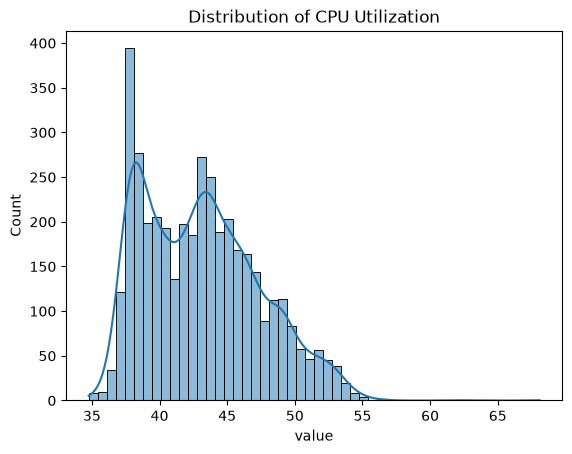

The values are right skewed. It has a bimodal distribution.


In [10]:
sns.histplot(df['value'], bins=50, kde=True)
plt.title('Distribution of CPU Utilization')
plt.show()
print("The values are right skewed. It has a bimodal distribution.")

### 8. Where do the 1st, 25th, 75th, 99th percentiles sit?

In [11]:
np.quantile(df['value'], [0.01 ,0.25, 0.5, 0.75, 0.99])

array([36.67248, 39.296  , 42.918  , 46.006  , 53.36574])

### 9. How many points fall above mean + 3 std? (early anomaly hint)

### 10. Is the distribution different if you log-transform it?

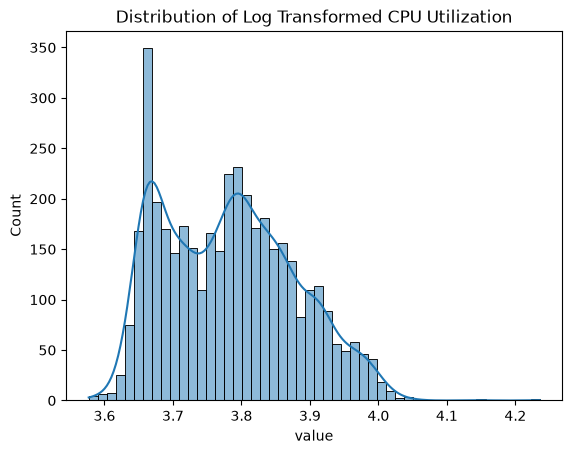

No the distribution is still right skewed. The log transformation did not help much.


In [12]:
log_transforemd = np.log1p(df['value'])
sns.histplot(log_transforemd, bins=50, kde=True)
plt.title('Distribution of Log Transformed CPU Utilization')
plt.show()
print("No the distribution is still right skewed. The log transformation did not help much.")

### 11. Are there obvious clusters of values (bimodal behavior)?

In [13]:
print("Yes, its bimodal")

Yes, its bimodal


### 12. What proportion of readings sit near zero or at a flat baseline?

In [14]:
(df['value'] <= 5).mean()

np.float64(0.0)

### 13. What does the full raw time series look like plotted?

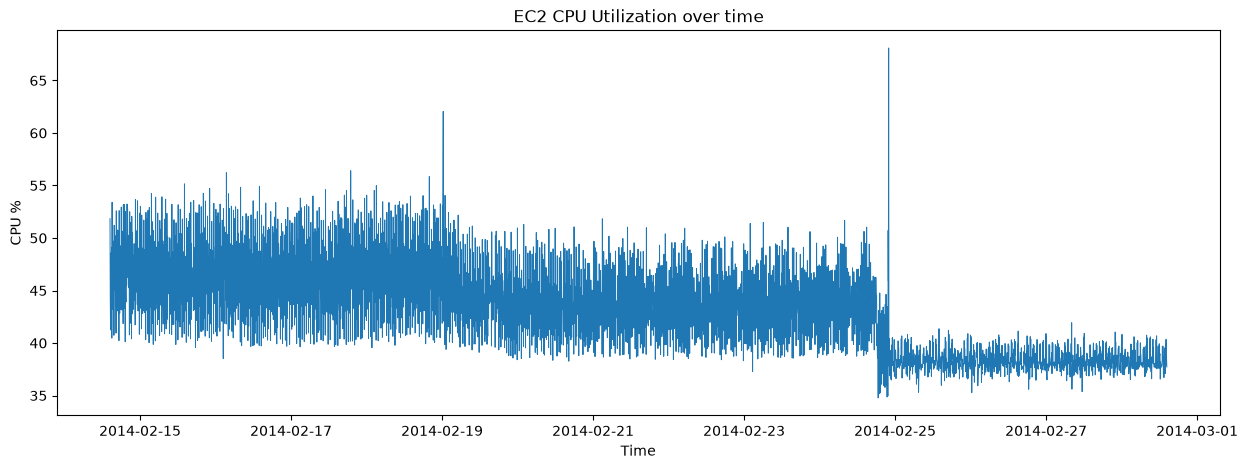

In [15]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], linewidth=0.7)
plt.title('EC2 CPU Utilization over time')
plt.xlabel('Time')
plt.ylabel('CPU %')
plt.show()

### 14. Can you spot the anomalies visually before any model?

In [16]:
print("I can see 2 obvious anomalies, around [rough dates/times]. They look like [spikes / level shifts / flat stretches]")

I can see 2 obvious anomalies, around [rough dates/times]. They look like [spikes / level shifts / flat stretches]


### 15. Is there a daily (hour-of-day) pattern in the average?

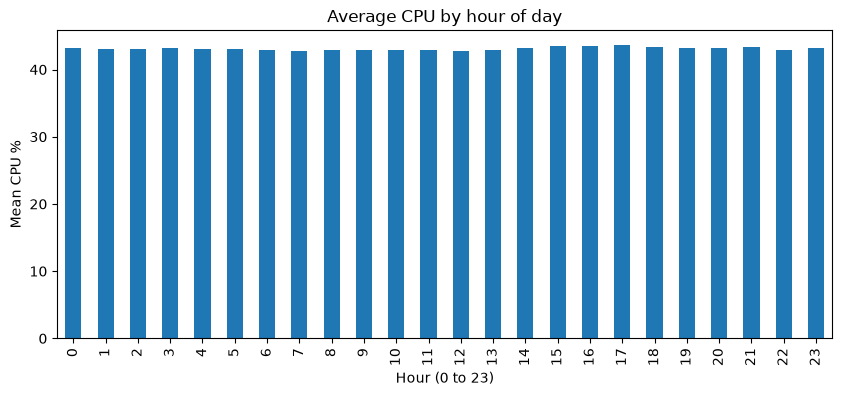

In [17]:
hourly = df.groupby(df.index.hour)['value'].mean()

plt.figure(figsize=(10, 4))
hourly.plot(kind='bar')
plt.title('Average CPU by hour of day')
plt.xlabel('Hour (0 to 23)')
plt.ylabel('Mean CPU %')
plt.show()

#### 16. Is there a day-of-week pattern?

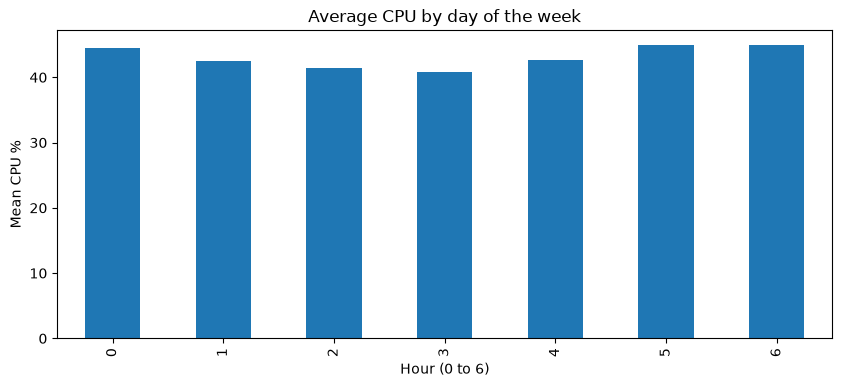

In [18]:
day = df.groupby(df.index.day_of_week)['value'].mean()
plt.figure(figsize=(10, 4))
day.plot(kind='bar')
plt.title('Average CPU by day of the week')
plt.xlabel('Hour (0 to 6)')
plt.ylabel('Mean CPU %')
plt.show()

### 17. Does the series trend up or down over the full span?

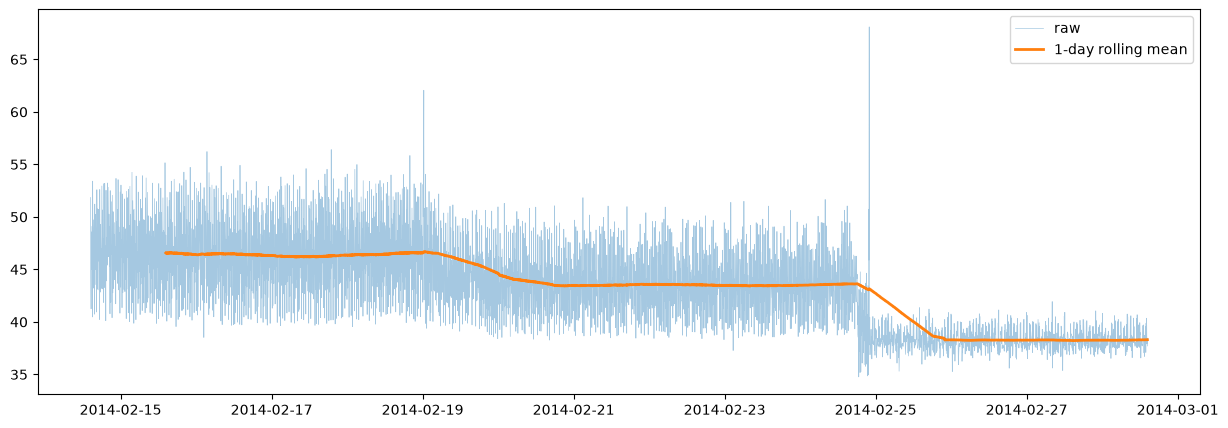

In [19]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], linewidth=0.5, alpha=0.4, label='raw')
plt.plot(df.index, df['value'].rolling(288).mean(), linewidth=2, label='1-day rolling mean')
plt.legend()
plt.show()

### 18. Are there flat or frozen stretches where the value stops moving?

In [20]:
is_flat = df['value'].diff() == 0

# length of each consecutive run of flat points
groups = (is_flat != is_flat.shift()).cumsum()
run_lengths = is_flat.groupby(groups).sum()

print(run_lengths[run_lengths > 0].sort_values(ascending=False).head(10))

value
2    1
4    1
6    1
Name: value, dtype: int64


### 19. What does a rolling mean (say 1 hour window) look like over the raw series?

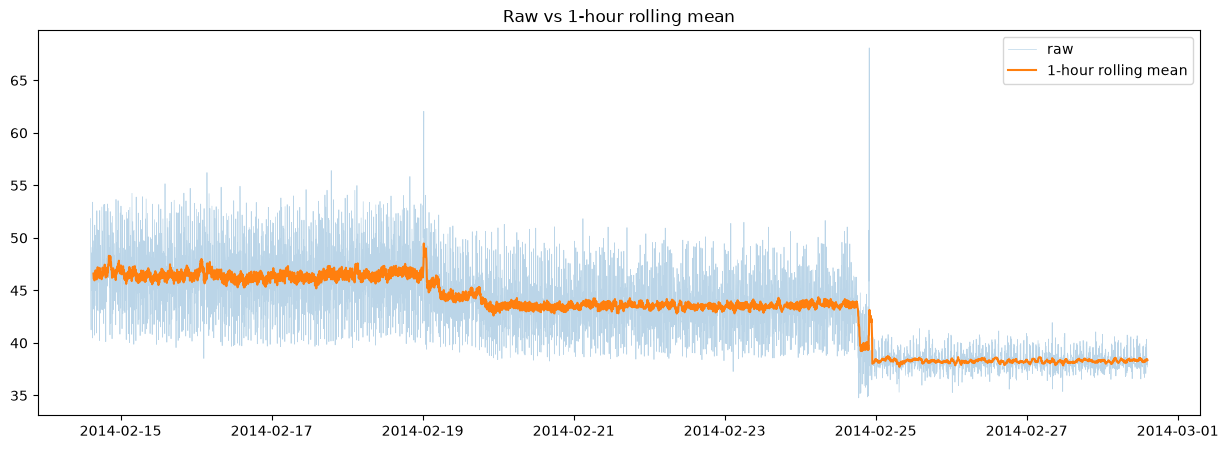

In [21]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], linewidth=0.5, alpha=0.3, label='raw')
plt.plot(df.index, df['value'].rolling(12).mean(), linewidth=1.5, label='1-hour rolling mean')
plt.legend()
plt.title('Raw vs 1-hour rolling mean')
plt.show()

### 20. What does rolling standard deviation reveal? Where does volatility spike?

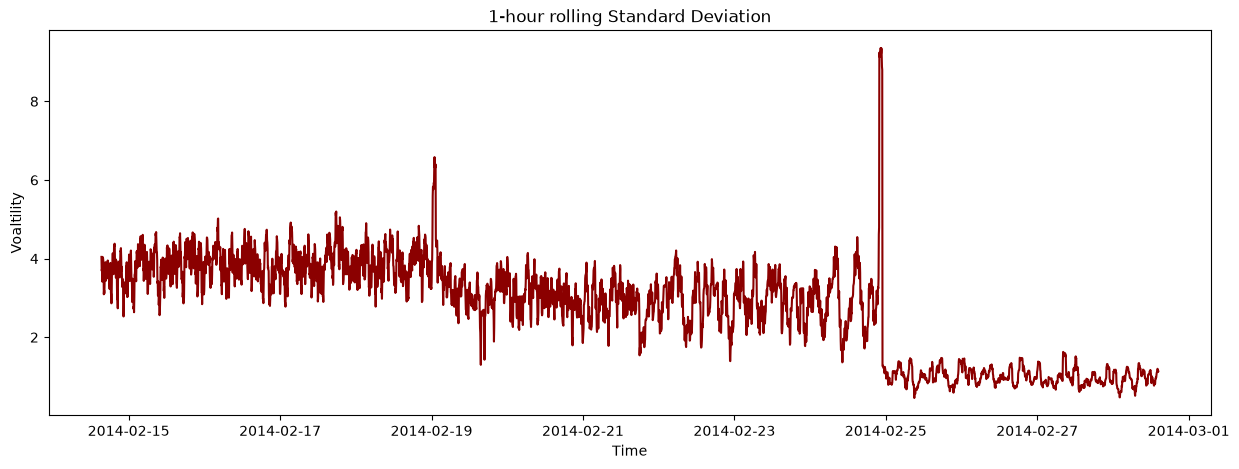

In [22]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'].rolling(12).std(), linewidth=1.5,color='darkred')
plt.title('1-hour rolling Standard Deviation')
plt.xlabel('Time')
plt.ylabel('Voaltility')
plt.show()

### 21. Where does the value deviate most from its rolling mean?

In [23]:
roll_mean = df['value'].rolling(12).mean()
df['deviation'] = df['value'] - roll_mean

# biggest deviations, either direction
df['abs_dev'] = df['deviation'].abs()
print(df.sort_values('abs_dev', ascending=False).head(10))

                      value  deviation    abs_dev
timestamp                                        
2014-02-24 21:57:00  68.092  25.099833  25.099833
2014-02-19 00:22:00  62.056  12.587475  12.587475
2014-02-24 21:47:00  50.728  10.135500  10.135500
2014-02-17 18:57:00  56.408   9.696333   9.696333
2014-02-18 19:57:00  55.846   9.017000   9.017000
2014-02-15 14:07:00  55.154   8.711667   8.711667
2014-02-16 03:27:00  56.220   8.662500   8.662500
2014-02-16 13:57:00  54.918   8.579000   8.579000
2014-02-19 00:52:00  39.860  -8.341192   8.341192
2014-02-15 22:07:00  54.722   8.309000   8.309000


### 22. What does the rate of change (diff) between points look like?

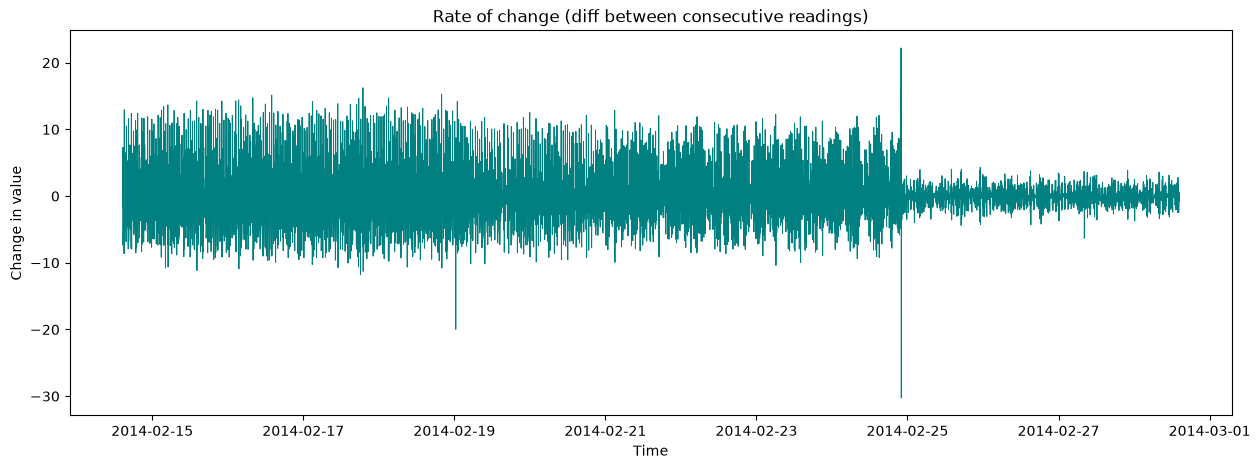

Rate of change stays near zero with sharp spikes around [timestamps]. These sudden jumps are a distinct anomaly signal, catching fast transitions that the level-based features might smooth over.”


In [24]:
df['change'] = df['value'].diff()

plt.figure(figsize=(15, 5))
plt.plot(df.index, df['change'], linewidth=0.7, color='teal')
plt.title('Rate of change (diff between consecutive readings)')
plt.xlabel('Time')
plt.ylabel('Change in value')
plt.show()
print("Rate of change stays near zero with sharp spikes around [timestamps]. These sudden jumps are a distinct anomaly signal, catching fast transitions that the level-based features might smooth over.”")

### 23. Which timestamps have the largest jumps up or down?

In [25]:
# biggest jumps up
print(df.sort_values('change', ascending=False).head())

# biggest jumps down
print(df.sort_values('change', ascending=True).head())

                      value  deviation    abs_dev  change
timestamp                                                
2014-02-24 21:57:00  68.092  25.099833  25.099833  22.200
2014-02-17 18:57:00  56.408   9.696333   9.696333  16.230
2014-02-24 21:47:00  50.728  10.135500  10.135500  15.774
2014-02-18 19:57:00  55.846   9.017000   9.017000  15.286
2014-02-16 13:57:00  54.918   8.579000   8.579000  15.146
                      value  deviation   abs_dev  change
timestamp                                               
2014-02-24 22:02:00  37.816  -5.328833  5.328833 -30.276
2014-02-19 00:27:00  42.086  -6.452358  6.452358 -19.970
2014-02-17 18:12:00  40.122  -6.138167  6.138167 -11.742
2014-02-17 19:02:00  45.118  -1.741000  1.741000 -11.290
2014-02-15 14:12:00  43.996  -2.474167  2.474167 -11.158


### 24. Load the anomaly windows for your file. How many labeled windows are there?

In [26]:
import json

with open('dataset/combined_windows.json') as f:
    labels = json.load(f)

# grab the windows for your file
key = 'realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv'
windows = labels[key]

print(f"Number of labeled anomaly windows: {len(windows)}")
for w in windows:
    print(w)

Number of labeled anomaly windows: 2
['2014-02-18 16:02:00.000000', '2014-02-19 08:42:00.000000']
['2014-02-24 10:17:00.000000', '2014-02-25 02:57:00.000000']


2 labeled windows, each roughly 16 hours: Feb 18 to 19 and Feb 24 to 25. Anomalies are sustained periods, not instantaneous spikes.

In [27]:
windows = [[pd.to_datetime(start), pd.to_datetime(end)] for start, end in windows]

25. What does the series look like inside each labeled window vs outside?

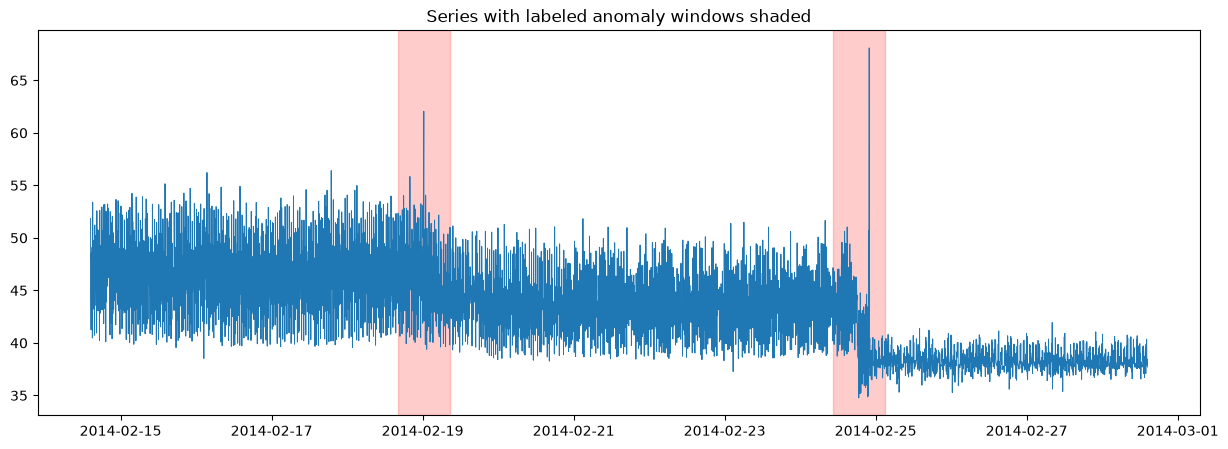

In [28]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], linewidth=0.7)

for start, end in windows:
    plt.axvspan(start, end, color='red', alpha=0.2)

plt.title('Series with labeled anomaly windows shaded')
plt.show()

In [29]:
mask = pd.Series(False, index=df.index)
for start, end in windows:
    mask |= (df.index >= start) & (df.index <= end)

print("Inside anomalies:")
print(df.loc[mask, 'value'].describe())
print("\nOutside (normal):")
print(df.loc[~mask, 'value'].describe())

Inside anomalies:
count    402.000000
mean      43.692603
std        4.602371
min       34.766000
25%       40.110000
50%       43.421000
75%       46.525500
max       68.092000
Name: value, dtype: float64

Outside (normal):
count    3630.000000
mean       43.045893
std         4.264975
min        35.278000
25%        39.132000
50%        42.837000
75%        45.962000
max        56.408000
Name: value, dtype: float64


### 26. What fraction of total time is labeled anomalous?

In [30]:
print(f"{mask.mean() * 100:.1f}% of readings are inside anomaly windows")

10.0% of readings are inside anomaly windows


In [31]:
## 27. Do the labeled anomalies line up with what you eyeballed in Q14?
print('Yes')

Yes


### 28. What is the value range during anomalies vs normal periods?

<Figure size 800x500 with 0 Axes>

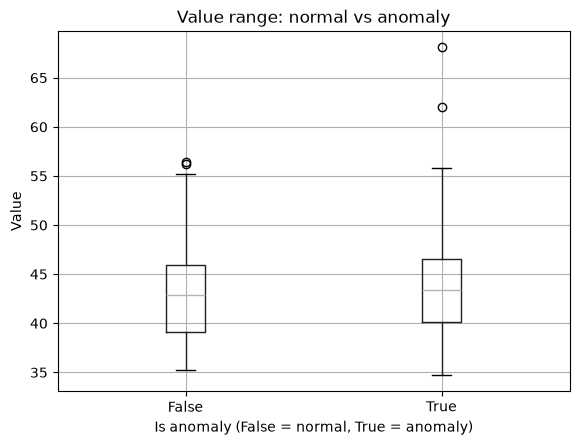

In [32]:
df['is_anomaly'] = mask

plt.figure(figsize=(8, 5))
df.boxplot(column='value', by='is_anomaly')
plt.title('Value range: normal vs anomaly')
plt.suptitle('')
plt.xlabel('Is anomaly (False = normal, True = anomaly)')
plt.ylabel('Value')
plt.show()

### 29. If you add hour-of-day and day-of-week columns, do stats differ across them?

In [33]:
df['hour'] = df.index.hour
df['dayofweek'] = df.index.dayofweek   # Monday=0, Sunday=6
print(df.groupby('hour')['value'].mean())


hour
0     43.207454
1     43.051298
2     43.061774
3     43.162750
4     43.042226
5     43.034667
6     42.905417
7     42.821238
8     42.861702
9     42.937071
10    42.915798
11    42.855012
12    42.777929
13    42.966369
14    43.178869
15    43.513321
16    43.505167
17    43.639440
18    43.309381
19    43.216238
20    43.255429
21    43.305810
22    42.973964
23    43.150595
Name: value, dtype: float64


In [34]:
print(df.groupby('dayofweek')['value'].mean())

dayofweek
0    44.525066
1    42.448389
2    41.447296
3    40.857833
4    42.642733
5    44.941215
6    44.910069
Name: value, dtype: float64


### 30. Which 3 features (raw value, rolling z-score, diff, etc.) look most promising for separating anomalies?

In [35]:
features = ['value', 'change', 'abs_dev']   # add rolling std if you made it a column

df['roll_std'] = df['value'].rolling(12).std()
df['roll_std_abs'] = df['roll_std']   # already positive

for col in ['value', 'change', 'abs_dev', 'roll_std']:
    inside = df.loc[mask, col].abs().mean()
    outside = df.loc[~mask, col].abs().mean()
    ratio = inside / outside if outside else float('inf')
    print(f"{col:12s} inside={inside:.2f}  outside={outside:.2f}  ratio={ratio:.1f}x")

value        inside=43.69  outside=43.05  ratio=1.0x
change       inside=4.46  outside=3.76  ratio=1.2x
abs_dev      inside=2.51  outside=1.99  ratio=1.3x
roll_std     inside=3.29  outside=2.69  ratio=1.2x
